Fashion mnist : CNN vs Random Forest

1. Seting up and getting the data

In [55]:
import numpy as np
import tensorflow as tf

random_seed = 40
pixelCount = 255.0
tf.keras.utils.set_random_seed(random_seed)
class_name = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Hills", "shirt", "sneaker", "bag", "boot" ]

fashionmnst = tf.keras.datasets.fashion_mnist;
(trainImages, trainLabels), (test_images, test_labels) = fashionmnst.load_data()
trainImages = trainImages/pixelCount;
test_images = test_images/pixelCount;
print(f"trainng img shape is : {trainImages.shape}")
print(f"Text img shapes : {test_images.shape}")

trainng img shape is : (60000, 28, 28)
Text img shapes : (10000, 28, 28)


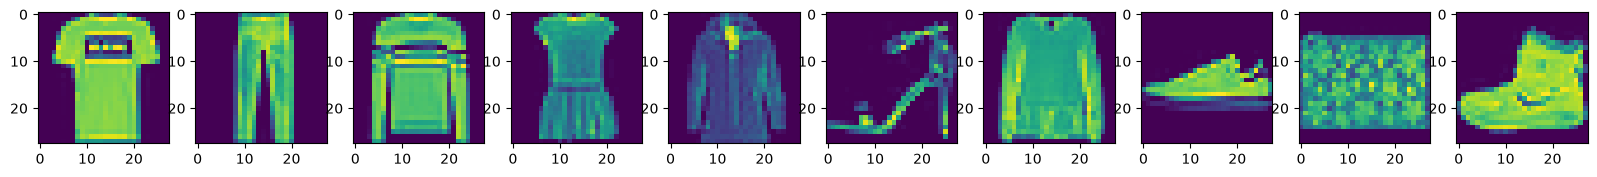

In [56]:
import matplotlib.pyplot as matplotplt

matplotplt.figure(figsize=(20,5))
for label in range(10):
    # trying to find the first img with this label.
    trainingLabelSizes = len(trainLabels);
    for i in range(trainingLabelSizes):
        if(trainLabels[i] == label ):
            firstImg = trainImages[i]
            break; # found it no reason to loop

    matplotplt.subplot(1,10, label+1)
    matplotplt.imshow(firstImg)
    lables = class_name[label]
    # matplotplt.title(lables)

matplotplt.show()

2. Training the cnn

Epoch 1/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.8649 - loss: 0.3812
Epoch 2/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.9108 - loss: 0.2447
Epoch 3/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9309 - loss: 0.1893
Epoch 4/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9470 - loss: 0.1463
Epoch 5/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9601 - loss: 0.1116
Epoch 6/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.9694 - loss: 0.0864
Epoch 7/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9747 - loss: 0.0691
Epoch 8/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.9798 - loss: 0.0548
Epoch 9/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9820 - loss: 0.0484
Epoch 10/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9845 - loss: 0.0428
Epoch 11/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.9869 - loss: 0.0357
Epoch 12/

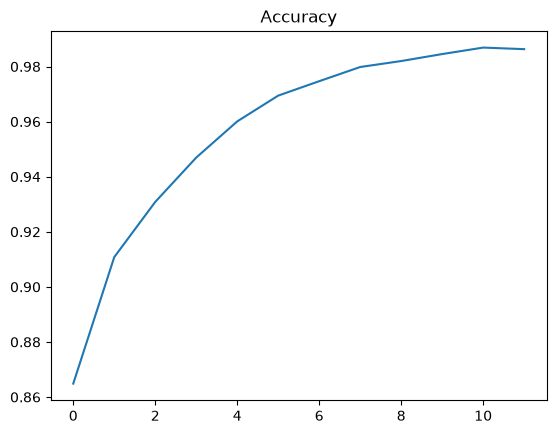

In [57]:
import matplotlib.pyplot as matplot
import time
lenTrainImages = len(trainImages)
lenTestImages = len(test_images)
pixel_width = 28
pixel_height = 28
cnnTrainImgs = trainImages.reshape(lenTrainImages, pixel_width,pixel_height,1)
cnnTestImgs = test_images.reshape(lenTestImages, pixel_width,pixel_height,1)

# sequential because the layers run sequentially one, after another
cnn = tf.keras.Sequential()

# now input layer
cnn.add(tf.keras.layers.Input(shape=(pixel_width, pixel_height, 1)))

# 32 small, 3 by 3 filters that tryies to find simple patters
cnn.add(tf.keras.layers.Conv2D(32,3,activation="relu"))

# shrinks the image by half
cnn.add(tf.keras.layers.MaxPooling2D())

# second layer
filter_sizes = 64 # the higher the number the slower but will learn better patterns.
cnn.add(tf.keras.layers.Conv2D(filter_sizes,3,activation="relu"))

# shirking it again, traing is faster when shrinked.
# cnn.add(tf.keras.layers.MaxPooling2D())

cnn.add(tf.keras.layers.Flatten())

cnn.add(tf.keras.layers.Dense(128, activation="relu"))
cnn.add(tf.keras.layers.Dense(10, activation="softmax"))

cnn.compile(
    optimizer="adam",                          
    loss="sparse_categorical_crossentropy",   
    metrics=["accuracy"],                     
)

startTimeForTraining = time.time()
# training start here 
history = cnn.fit(cnnTrainImgs, trainLabels, epochs=12)
# training ends here

trainingEndTime = time.time()
cnnTime = trainingEndTime - startTimeForTraining
# now let's draw the results
matplot.plot(history.history['accuracy'])
matplot.title("Accuracy")
matplot.show()


3. Training random forest here, the classifieer by Xiao

In [58]:
from sklearn.ensemble import RandomForestClassifier
trainImagesLen = len(trainImages)
testImagesLen = len(test_images)
pixels1Dimension = 28 * 28 # why? because, random forest cant work with 2d imges it should be a flat images so i am just converting it to 1 dimension img ( the original 28x28 is theimg size)
forestTrainIMgs = trainImages.reshape(trainImagesLen, pixels1Dimension)
forestTestImgs = test_images.reshape(testImagesLen, pixels1Dimension)

forest = RandomForestClassifier(
    random_state=42,
    max_depth = 100,
    n_estimators = 100,
    criterion='entropy',
)
forestStartTime = time.time()
forest.fit(forestTrainIMgs, trainLabels);
forestEndTime = time.time()
forestTrainingTime = forestEndTime - forestStartTime


4. Doing predictions, Evaluating both classifers

In [59]:
cnnTrainProbabilities = cnn.predict(cnnTrainImgs)
cnnTestProbabilities = cnn.predict(cnnTestImgs)

cnnTrainPredictions = np.argmax(cnnTrainProbabilities, axis = 1)
cnnTestPredictions = np.argmax(cnnTestProbabilities, axis = 1)

forestTrainPredictions = forest.predict(forestTrainIMgs);
forestTestPredictions = forest.predict(forestTestImgs);



1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


5. Confusion matrix, draw confusion matrix.


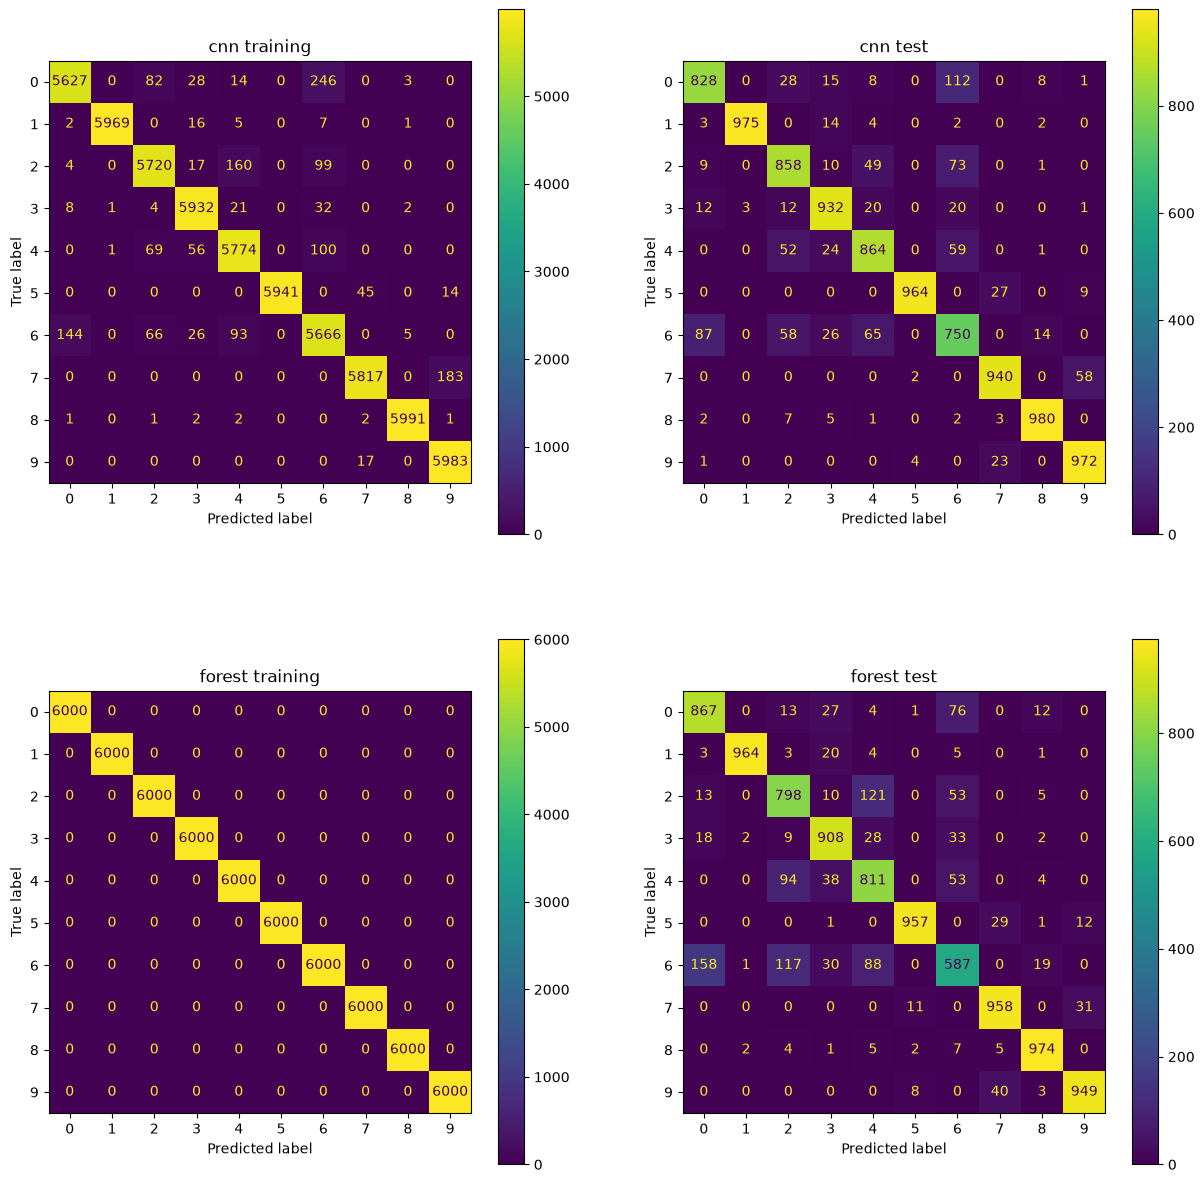

In [60]:
# creating a fun that will draw this matrix images, i will be doing it 4 times, and that's why i created the function
import matplotlib.pyplot as matplotplt
from sklearn.metrics import ConfusionMatrixDisplay 
def drawMatrix(title, correctLbl, thePredictedLbl, position):
    axis = matplotplt.subplot(2, 2, position)

    ConfusionMatrixDisplay.from_predictions(
        correctLbl,
        thePredictedLbl,
        ax=axis
    )
    axis.set_title(title)

matplotplt.figure(figsize=(15,15))
drawMatrix("cnn training", trainLabels, cnnTrainPredictions, 1);
drawMatrix("cnn test", test_labels, cnnTestPredictions, 2)
drawMatrix("forest training", trainLabels, forestTrainPredictions, 3)
drawMatrix("forest test", test_labels, forestTestPredictions, 4)

matplotplt.show()

6. precision and recall per class, a table presenting precision and recall value

In [61]:
import pandas as pd
from sklearn.metrics import precision_score as precision_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

scores = pd.DataFrame(index=class_name)
# cnn scores
scores["cnn precesion train"] = precision_score(trainLabels, cnnTrainPredictions, average=None)
scores["cnn recall train"] = recall_score(trainLabels, cnnTrainPredictions, average=None)
scores["cnn precesion test"] = precision_score(test_labels, cnnTestPredictions, average=None)
scores["cnn recall test"] = recall_score(test_labels, cnnTestPredictions, average=None)

# random forest scores
scores['forest precesion train'] = precision_score(trainLabels, forestTrainPredictions, average=None)
scores['forest recall train'] = recall_score(trainLabels, forestTrainPredictions, average=None)
scores['forest precesion test'] = precision_score(test_labels, forestTestPredictions, average=None)
scores['forest recall test'] = recall_score(test_labels, forestTestPredictions, average=None)


scores.loc['Average'] = scores.mean()
scores.round(4)



,cnn precesion train,cnn recall train,cnn precesion test,cnn recall test,forest precesion train,forest recall train,forest precesion test,forest recall test
T-shirt,0.9725,0.9378,0.8790,0.8280,1.0,1.0,0.8187,0.8670
Trouser,0.9997,0.9948,0.9969,0.9750,1.0,1.0,0.9948,0.9640
Pullover,0.9626,0.9533,0.8453,0.8580,1.0,1.0,0.7688,0.7980
Dress,0.9761,0.9887,0.9084,0.9320,1.0,1.0,0.8773,0.9080
Coat,0.9514,0.9623,0.8546,0.8640,1.0,1.0,0.7644,0.8110
Hills,1.0000,0.9902,0.9938,0.9640,1.0,1.0,0.9775,0.9570
shirt,0.9213,0.9443,0.7367,0.7500,1.0,1.0,0.7211,0.5870
sneaker,0.9891,0.9695,0.9466,0.9400,1.0,1.0,0.9283,0.9580
bag,0.9982,0.9985,0.9742,0.9800,1.0,1.0,0.9540,0.9740
boot,0.9680,0.9972,0.9337,0.9720,1.0,1.0,0.9567,0.9490


7. Accuracy and Training time for each classifer

In [62]:
cnnTrainAccuracy = accuracy_score(trainLabels, cnnTrainPredictions)
cnnTestAccuracy = accuracy_score(test_labels, cnnTestPredictions)
forestTrainAccuracy = accuracy_score(trainLabels, forestTrainPredictions)
forestTestAccuracy = accuracy_score(test_labels, forestTestPredictions)
finalReport = pd.DataFrame(index=["Cnn", "random forest"])
finalReport["Train accuracy"] = [cnnTrainAccuracy, forestTrainAccuracy]
finalReport["Test accuracy"] = [cnnTestAccuracy, forestTestAccuracy]
finalReport["training time in seconds"] = [cnnTime, forestTrainingTime]
finalReport.round(4)

,Train accuracy,Test accuracy,training time in seconds
Cnn,0.9737,0.9063,249.5159
random forest,1.0000,0.8773,95.8632


8. Worst categories

In [63]:
f1Table = pd.DataFrame(index=class_name)
f1Table["cnn f1"] = f1_score(test_labels, cnnTestPredictions, average=None)
f1Table["forest f1"] = f1_score(test_labels, forestTestPredictions, average=None)
f1Table = f1Table.sort_values("cnn f1")
f1Table.round(4)

,cnn f1,forest f1
shirt,0.7433,0.6472
Pullover,0.8516,0.7831
T-shirt,0.8527,0.8422
Coat,0.8593,0.7870
Dress,0.9200,0.8924
sneaker,0.9433,0.9429
boot,0.9525,0.9528
bag,0.9771,0.9639
Hills,0.9787,0.9672
Trouser,0.9858,0.9792


the cnn thinks  250  items are wrongly  shirt


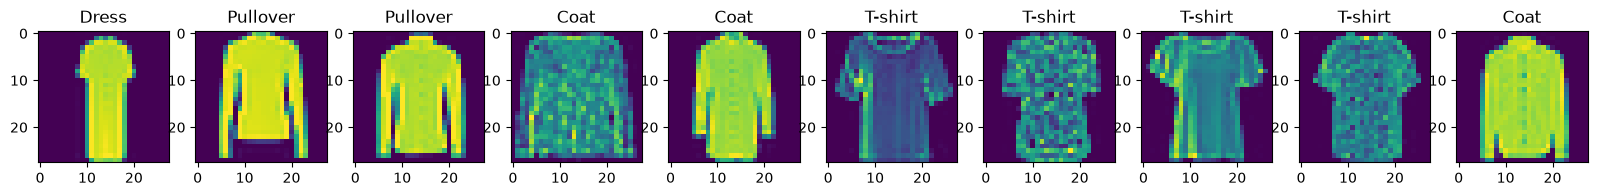

the cnn thinks  142  items are wrongly  pullover


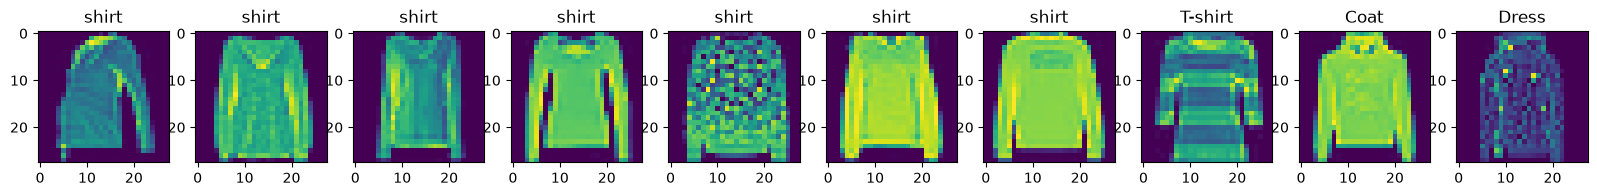

In [64]:
import matplotlib.pyplot as plt

def worstCategoryIdentifer(itemIndex, itemName):
    shirt = itemIndex # the worst category according to the table above
    wrongly_classified_as_shirts = []
    how_many_to_show = 10

    for imgsNumber in range(len(test_labels)):
        realClass = test_labels[imgsNumber]
        predictedClass = cnnTestPredictions[imgsNumber]
        if realClass == shirt and predictedClass != shirt:
            wrongly_classified_as_shirts.append(imgsNumber)
    print("the cnn thinks ", len(wrongly_classified_as_shirts), " items are wrongly ", itemName)

    plt.figure(figsize=(20,5))
    for count in range(how_many_to_show):
        imgsNumber = wrongly_classified_as_shirts[count]
        image = test_images[imgsNumber]
        predictedClass = cnnTestPredictions[imgsNumber]
        predictedName = class_name[predictedClass]

        plt.subplot(1, how_many_to_show, count + 1);
        plt.imshow(image)
        plt.title(predictedName)

    plt.show()

worstCategoryIdentifer(6, "shirt"); # 6 is shirt
worstCategoryIdentifer(2, "pullover"); # 2 is pullover